In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

Text(0, 0.5, 'Y Dataset')

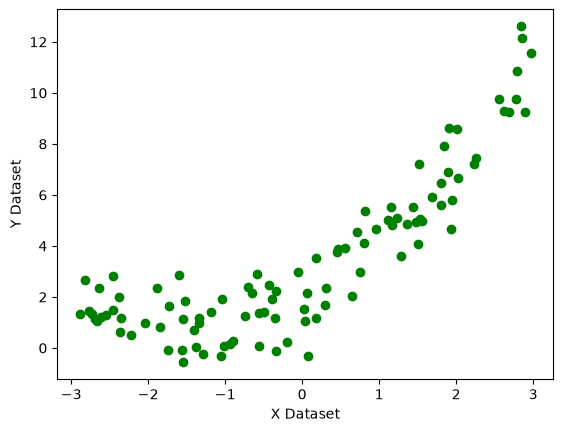

In [6]:
X = 6 * np.random.rand(100, 1) - 3
y = 0.5 * X**2 + 1.5 *X + 2 + np.random.randn(100, 1)
plt.scatter(X, y,color='g')
plt.xlabel('X Dataset')
plt.ylabel('Y Dataset')

In [7]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [8]:
## simple linear regression
from sklearn.linear_model import LinearRegression
regression_1 = LinearRegression()

In [9]:
regression_1.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[1.48]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[3.53]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[15.27]


In [10]:
from sklearn.metrics import r2_score
score = r2_score(y_test, regression_1.predict(X_test))
print(score)

0.6607142783721753


Text(0, 0.5, 'Y')

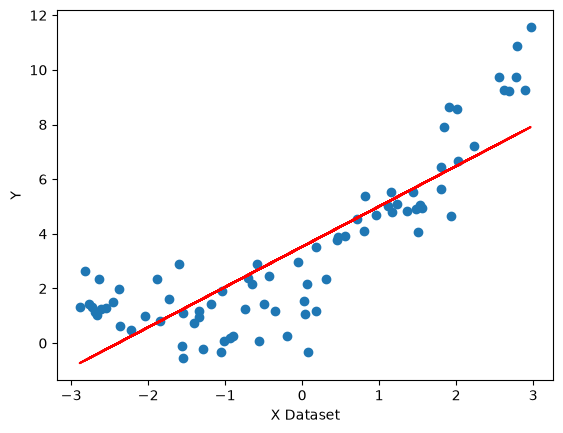

In [14]:
## Visualizing model
plt.plot(X_train, regression_1.predict(X_train), color='r')
plt.scatter(X_train, y_train)
plt.xlabel("X Dataset")
plt.ylabel("Y")

In [15]:
## Polynomial transformation
from sklearn.preprocessing import PolynomialFeatures

In [16]:
poly = PolynomialFeatures(degree=2, include_bias=True)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

In [17]:
X_train_poly

array([[ 1.00000000e+00,  4.71187738e-01,  2.22017884e-01],
       [ 1.00000000e+00, -5.22936971e-02,  2.73463076e-03],
       [ 1.00000000e+00, -2.46188592e+00,  6.06088228e+00],
       [ 1.00000000e+00, -1.18604399e+00,  1.40670034e+00],
       [ 1.00000000e+00, -6.98234492e-01,  4.87531405e-01],
       [ 1.00000000e+00, -2.66254100e+00,  7.08912460e+00],
       [ 1.00000000e+00, -1.73505469e+00,  3.01041477e+00],
       [ 1.00000000e+00, -3.54375296e-01,  1.25581850e-01],
       [ 1.00000000e+00,  1.35604306e+00,  1.83885279e+00],
       [ 1.00000000e+00,  2.61668616e+00,  6.84704646e+00],
       [ 1.00000000e+00,  2.89701885e+00,  8.39271823e+00],
       [ 1.00000000e+00, -1.40401665e+00,  1.97126274e+00],
       [ 1.00000000e+00,  2.23263034e+00,  4.98463822e+00],
       [ 1.00000000e+00,  7.06595712e-01,  4.99277500e-01],
       [ 1.00000000e+00,  1.85352948e-01,  3.43557154e-02],
       [ 1.00000000e+00, -2.38084046e+00,  5.66840131e+00],
       [ 1.00000000e+00, -2.03884948e+00

In [18]:
from sklearn.metrics import r2_score
regression = LinearRegression()
regression.fit(X_train_poly, y_train)
y_pred = regression.predict(X_test_poly)
score = r2_score(y_test, y_pred)
print(score)

0.9042995757804706


In [19]:
print(regression.coef_)

[[0.         1.53131946 0.48012279]]


In [20]:
print(regression.intercept_)

[2.12967947]


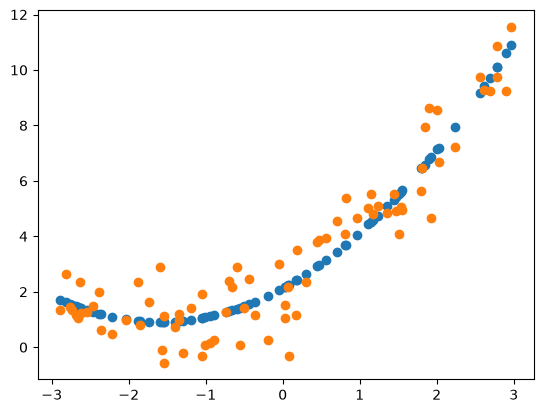

In [23]:
plt.scatter(X_train, regression.predict(X_train_poly))
plt.scatter(X_train, y_train)

In [24]:
poly = PolynomialFeatures(degree=3, include_bias=True)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

In [25]:
X_train_poly

array([[ 1.00000000e+00,  4.71187738e-01,  2.22017884e-01,
         1.04612105e-01],
       [ 1.00000000e+00, -5.22936971e-02,  2.73463076e-03,
        -1.43003953e-04],
       [ 1.00000000e+00, -2.46188592e+00,  6.06088228e+00,
        -1.49212007e+01],
       [ 1.00000000e+00, -1.18604399e+00,  1.40670034e+00,
        -1.66840849e+00],
       [ 1.00000000e+00, -6.98234492e-01,  4.87531405e-01,
        -3.40411243e-01],
       [ 1.00000000e+00, -2.66254100e+00,  7.08912460e+00,
        -1.88750849e+01],
       [ 1.00000000e+00, -1.73505469e+00,  3.01041477e+00,
        -5.22323426e+00],
       [ 1.00000000e+00, -3.54375296e-01,  1.25581850e-01,
        -4.45031052e-02],
       [ 1.00000000e+00,  1.35604306e+00,  1.83885279e+00,
         2.49356357e+00],
       [ 1.00000000e+00,  2.61668616e+00,  6.84704646e+00,
         1.79165717e+01],
       [ 1.00000000e+00,  2.89701885e+00,  8.39271823e+00,
         2.43138629e+01],
       [ 1.00000000e+00, -1.40401665e+00,  1.97126274e+00,
      

In [26]:
from sklearn.metrics import r2_score
regression = LinearRegression()
regression.fit(X_train_poly, y_train)
y_pred = regression.predict(X_test_poly)
score = r2_score(y_test, y_pred)
print(score)

0.8985036700540896


In [28]:
## Prediction of new data

X_new = np.linspace(-3, 3, 200).reshape(200, 1)
X_new_poly = poly.transform(X_new)
X_new_poly

array([[ 1.00000000e+00, -3.00000000e+00,  9.00000000e+00,
        -2.70000000e+01],
       [ 1.00000000e+00, -2.96984925e+00,  8.82000455e+00,
        -2.61940839e+01],
       [ 1.00000000e+00, -2.93969849e+00,  8.64182723e+00,
        -2.54043665e+01],
       [ 1.00000000e+00, -2.90954774e+00,  8.46546804e+00,
        -2.46306834e+01],
       [ 1.00000000e+00, -2.87939698e+00,  8.29092700e+00,
        -2.38728702e+01],
       [ 1.00000000e+00, -2.84924623e+00,  8.11820409e+00,
        -2.31307624e+01],
       [ 1.00000000e+00, -2.81909548e+00,  7.94729931e+00,
        -2.24041955e+01],
       [ 1.00000000e+00, -2.78894472e+00,  7.77821267e+00,
        -2.16930052e+01],
       [ 1.00000000e+00, -2.75879397e+00,  7.61094417e+00,
        -2.09970269e+01],
       [ 1.00000000e+00, -2.72864322e+00,  7.44549380e+00,
        -2.03160961e+01],
       [ 1.00000000e+00, -2.69849246e+00,  7.28186157e+00,
        -1.96500486e+01],
       [ 1.00000000e+00, -2.66834171e+00,  7.12004747e+00,
      

<function matplotlib.pyplot.show(close=None, block=None)>

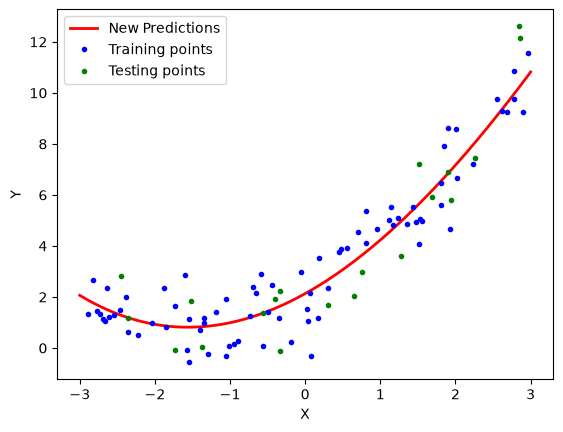

In [31]:
y_new = regression.predict(X_new_poly)
plt.plot(X_new, y_new, 'r-', linewidth=2, label='New Predictions')
plt.plot(X_train, y_train, "b.", label="Training points")
plt.plot(X_test, y_test, "g.", label="Testing points")
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.show

## Pipeline

In [34]:
from sklearn.pipeline import Pipeline

In [54]:
def poly_regression(degree):
    X_new = np.linspace(-3, 3, 200).reshape(200, 1)
    
    poly_features= PolynomialFeatures(degree=degree, include_bias=True)
    lin_reg = LinearRegression()
    poly_regression= Pipeline([
        ("poly_features", poly_features),
        ("lin_reg", lin_reg)
    ])
    poly_regression.fit(X_train, y_train)
    y_pred_new=poly_regression.predict(X_new)
    
    #plotting prediction line
    plt.plot(X_new, y_pred_new, 'r', label='Degree ' + str(degree), linewidth=3)
    plt.plot(X_train, y_train, 'b.', linewidth=3)
    plt.plot(X_test, y_test, 'g.', linewidth=3)
    plt.legend(loc="upper left")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.axis([-4, 4, 0, 10])
    plt.show()
    

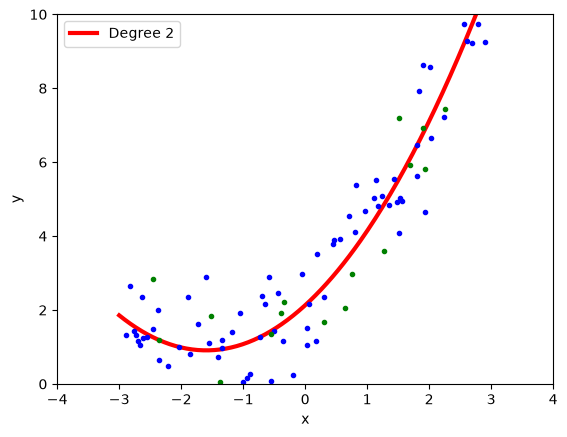

In [58]:
poly_regression(2)